In This notebook we explore the Register Token Embeddings of COCO Datasets (2014 and 2017). The exploration of the ImageNet100 Dataset (See ImageNet100 Notebook) yielded some key observations that we will be exploring in depth. 

In [3]:
import os
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from PIL import Image
import torchvision.transforms as T
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Load Data and Compute Embeddings 

In [1]:
from datasets import load_dataset

# Load the COCO dataset
def load_coco_dataset(subset_size=1000):
    # Load the dataset
    ds = load_dataset("detection-datasets/coco")
    train_ds = ds['train']

    # Select a subset of the dataset (e.g., 1000 images)
    train_ds = train_ds.select(range(subset_size))
    return train_ds

train_ds = load_coco_dataset()

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/20 [00:00<?, ?it/s]

In [4]:
dinov2_vits14 = torch.hub.load('C:/Users/pninaklein/dinov2/DINOv2RegisterExploration', 'dinov2_vits14_reg', source='local')
device = torch.device('cuda' if torch.cuda.is_available() else "cpu")
dinov2_vits14.to(device)

transform_image = T.Compose([T.ToTensor(), T.Resize(244), T.CenterCrop(224), T.Normalize([0.5], [0.5])])

C:\Users/pninaklein/dinov2/DINOv2RegisterExploration\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users/pninaklein/dinov2/DINOv2RegisterExploration\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users/pninaklein/dinov2/DINOv2RegisterExploration\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


In [5]:
embeddings_data = []

# Iterate over the dataset and compute embeddings
for sample in tqdm(train_ds, desc="Processing images", unit="image"):
    # Convert image to RGB and transform
    image = sample['image'].convert("RGB")  # Ensure the image is in RGB format
    transformed_image = transform_image(image).unsqueeze(0).to(device)  # Apply the transformation and add batch dimension

    with torch.no_grad():
        # Compute embeddings using your modified model
        embeddings = dinov2_vits14(transformed_image, return_register_tokens=True)
        patch_tokens, class_tokens, register_tokens = embeddings[0]

    # Extract bounding box and category labels
    boxes = sample['objects']['bbox']
    categories = sample['objects']['category']

    # Ensure boxes and categories are lists of lists (if not already)
    if not isinstance(boxes[0], list):
        boxes = [boxes]
    if not isinstance(categories, list):
        categories = [categories]

    # Append to embeddings_data ensuring everything is a tensor
    embeddings_data.append({
        "class_tokens": class_tokens.cpu(),
        "register_tokens": register_tokens.cpu(),
    })

print("Embeddings and labels prepared successfully!")


Processing images: 100%|██████████| 1000/1000 [02:08<00:00,  7.77image/s]

Embeddings and labels prepared successfully!


# Euclidean Distance

The first thing we present is the exploration of the Register Tokens behaviors as compared to the CLS Token. Similarly to the ImageNet100 Dataset, we expect to see here that all the registers behave similarly, except for Register 2 that is orthogonal to the CLS Token. 

In [6]:
from sklearn.metrics.pairwise import euclidean_distances
import numpy as np
import matplotlib.pyplot as plt

# Initialize a matrix for Euclidean distance bins
all_distances= []

# Calculate Euclidean distances and bin frequencies
for img in embeddings_data:
    cls_token = np.array(img['class_tokens'][0].tolist()).reshape(1, -1)
    im_distances= []
    for i in range(4):
        register_token = np.array(img['register_tokens'][0][i].tolist()).reshape(1, -1)
        
        # Compute Euclidean distance between CLS and register tokens
        distance = euclidean_distances(cls_token, register_token)[0][0]
        im_distances.append(distance)
    all_distances.append(im_distances)

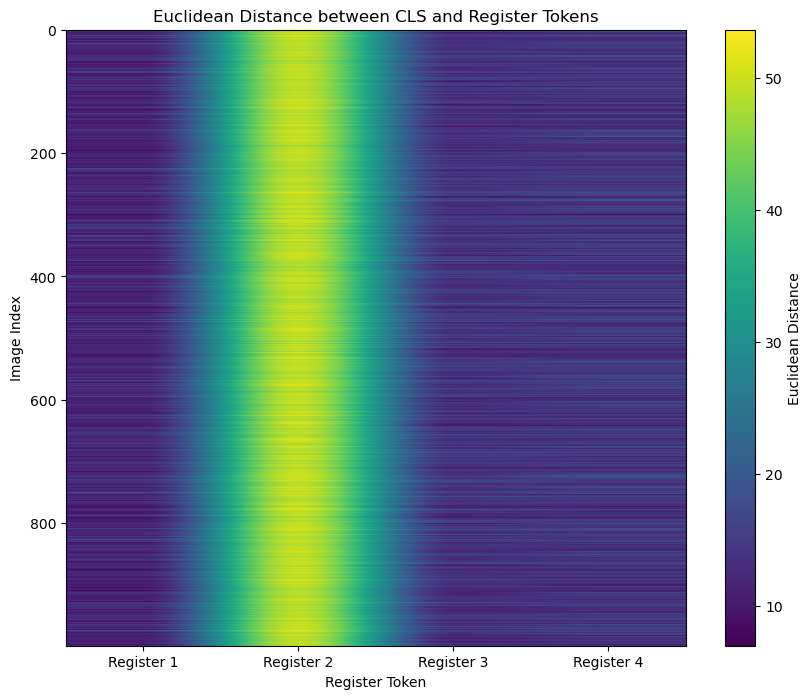

In [7]:
distance_array = np.array(all_distances)  # Shape should be (1000, 4)

# Plotting the heatmap
plt.figure(figsize=(10, 8))
plt.imshow(distance_array, cmap='viridis', aspect='auto')
plt.colorbar(label='Euclidean Distance')
plt.title('Euclidean Distance between CLS and Register Tokens')
plt.xlabel('Register Token')
plt.ylabel('Image Index')
plt.xticks(ticks=range(4), labels=[f'Register {i+1}' for i in range(4)])
plt.show()

# Cosine Similarity

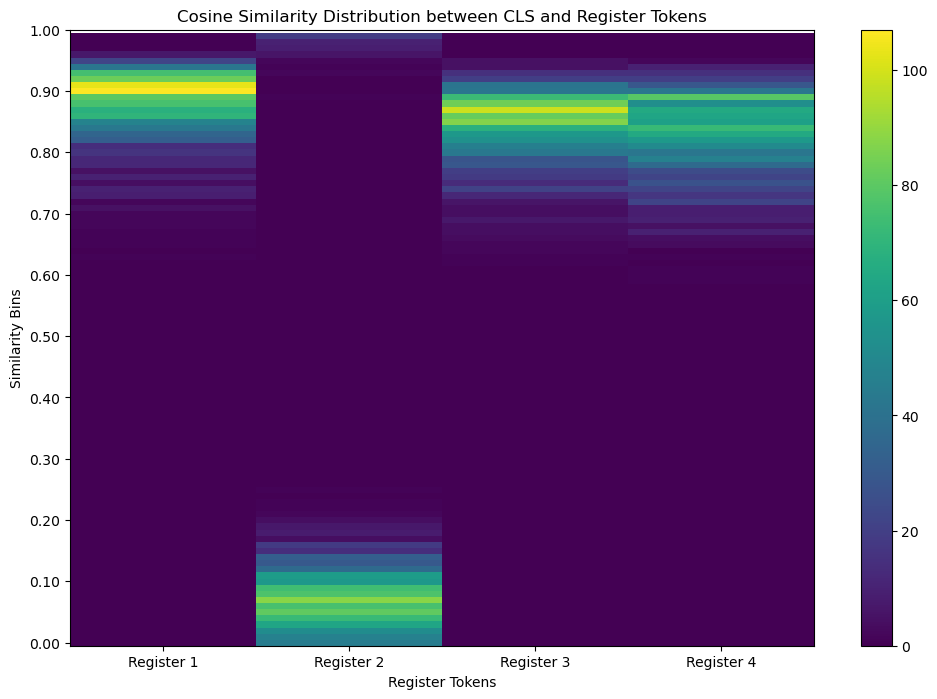

In [9]:
# Calculate similarities and bin frequencies
similarities = np.zeros((100, 4))
for img in embeddings_data:
    cls_token = np.array(img['class_tokens'][0].tolist()).reshape(1, -1)
    for i in range(4):
        register_token = np.array(img['register_tokens'][0][i].tolist()).reshape(1, -1)
        similarity = cosine_similarity(cls_token, register_token)[0][0]
        curr_bin = int(100 * similarity)
        curr_bin = min(curr_bin, 99)  # Ensure index is within bounds
        similarities[curr_bin, i] += 1
        
# Plotting the heatmap
def plot_similarity_heatmap(similarities):
    fig, ax = plt.subplots(figsize=(12, 8))
    cax = ax.matshow(similarities, cmap='viridis', aspect='auto')  # Set aspect to auto for a better fit
    plt.title('Cosine Similarity Distribution between CLS and Register Tokens')
    plt.xlabel('Register Tokens')
    plt.ylabel('Similarity Bins')
    plt.colorbar(cax)
    ax.xaxis.set_ticks_position('bottom')
    ax.invert_yaxis() 
    ax.set_xticks(range(4))
    ax.set_xticklabels([f'Register {i}' for i in range(1, 5)])
    ax.set_yticks(range(0, 101, 10))
    ax.set_yticklabels([f'{i/100:.2f}' for i in range(0, 101, 10)])
    plt.show()

plot_similarity_heatmap(similarities)

# Orthogonality

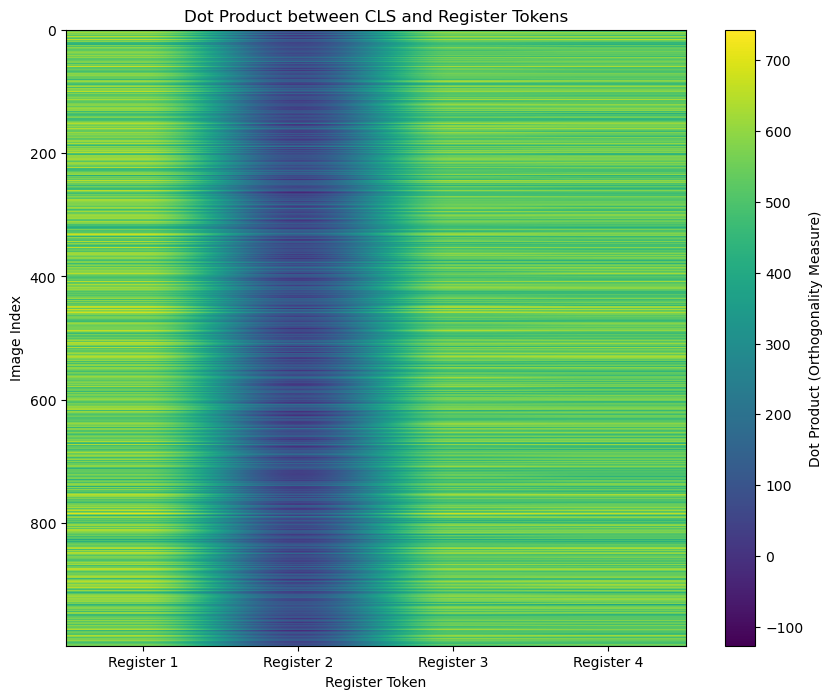

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Initialize a list to store dot products (orthogonality measure) for each register
all_dot_products = []

# Calculate the dot product between CLS token and register tokens
for img in embeddings_data:
    cls_token = np.array(img['class_tokens'][0].tolist()).reshape(-1)
    dot_products = []
    for i in range(4):
        register_token = np.array(img['register_tokens'][0][i].tolist()).reshape(-1)
        
        # Compute dot product between CLS and register tokens
        dot_product = np.dot(cls_token, register_token)
        dot_products.append(dot_product)
    all_dot_products.append(dot_products)

# Convert to a numpy array for easier plotting
dot_product_array = np.array(all_dot_products)  # Shape (1000, 4)

# Min-Max Normalization
min_val = np.min(dot_product_array)
max_val = np.max(dot_product_array)
normalized_dot_product_array = (dot_product_array - min_val) / (max_val - min_val)

# Plotting the heatmap
plt.figure(figsize=(10, 8))
plt.imshow(dot_product_array, cmap='viridis', aspect='auto')
plt.colorbar(label='Dot Product (Orthogonality Measure)')
plt.title('Dot Product between CLS and Register Tokens')
plt.xlabel('Register Token')
plt.ylabel('Image Index')
plt.xticks(ticks=range(4), labels=[f'Register {i+1}' for i in range(4)])
plt.show()


# Classification Comparison 

In this section, we will train various classification models, each on a distinct set of embeddings: the Register token embeddings, the CLS token embedding, and a combination of the CLS token with Register 2. We anticipate that, as with the previous results from the ImageNet100 model, all registers will yield reasonably accurate classifications, with Register 2 performing the weakest. However, unlike the ImageNet100 results, we expect the model's performance on the CLS token embedding to improve when Register 2 is added.

Note: Since we are using an object detection dataset there are multiple labels for each image. We will define the label of the image to be the largest object in the image (hence the object with the largest bounding box). This decision is based on trial and error with other common methods (such as picking the most common label). 

In [11]:
def get_largest_object_labels(dataset):
    labels = []
    for sample in dataset:
        categories = sample['objects']['category']
        bboxes = sample['objects']['bbox']  

        if categories and bboxes:
            areas = [(bbox[2] * bbox[3]) for bbox in bboxes] 
            largest_index = areas.index(max(areas))  
            labels.append(categories[largest_index])  
        else:
            labels.append(None)  

    return labels

labels = get_largest_object_labels(train_ds)


In [41]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tqdm import trange

def prepare_data(embeddings_data, labels, tokens= ['class_tokens', 'register_tokens'], reg=0):
    X = []
    y = []
    for img, label in zip(embeddings_data, labels):
        if len(tokens)> 1:
            first = np.array(img[tokens[0]][0].tolist()) #cls
            second = np.array(img[tokens[1]][0][1].tolist()) #register 2
            concatenated_embedding = np.concatenate((first, second))
        else: 
            if tokens[0]== 'register_tokens':
                concatenated_embedding = np.array(img[tokens[0]][0][reg].tolist())
            else: 
                concatenated_embedding = np.array(img[tokens[0]][reg].tolist())
                
        X.append(concatenated_embedding)
        y.append(label)
    return np.array(X), np.array(y)

def create_dataloaders(X, y, batch_size=32, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)
    train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
    test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader, max(y) +1

class SimpleClassifier(nn.Module):
    def __init__(self, input_size, num_classes):
        super(SimpleClassifier, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(256, num_classes)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

def train_model(train_loader, test_loader, input_size, num_epochs=10):
    train_accuracy = []
    test_accuracy = []
    
    model = SimpleClassifier(input_size, num_classes)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)

    for epoch in trange(num_epochs):
        model.train()
        correct_train = 0
        total_train = 0

        # Training phase
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            # Forward pass
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)

            # Backward pass and optimization
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Calculate training accuracy
            _, predicted = torch.max(outputs, 1)
            correct_train += (predicted == batch_y).sum().item()
            total_train += batch_y.size(0)

        train_accuracy.append(correct_train / total_train)

        # Evaluation phase for test accuracy
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for batch_X, batch_y in test_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                outputs = model(batch_X)
                _, predicted = torch.max(outputs, 1)
                correct_test += (predicted == batch_y).sum().item()
                total_test += batch_y.size(0)

        test_accuracy.append(correct_test / total_test)

    return train_accuracy, test_accuracy

In [42]:
def plot_accuracy(train_acc, val_acc, title):
    # Plotting
    plt.figure(figsize=(10, 5))
    plt.plot(train_acc, label='Train Accuracy')
    plt.plot(val_acc, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(title+ ' (max accuracy: '+str(max(val_acc)) +')')
    plt.legend()
    plt.grid(True)
    plt.show()

100%|██████████| 100/100 [00:02<00:00, 33.42it/s]


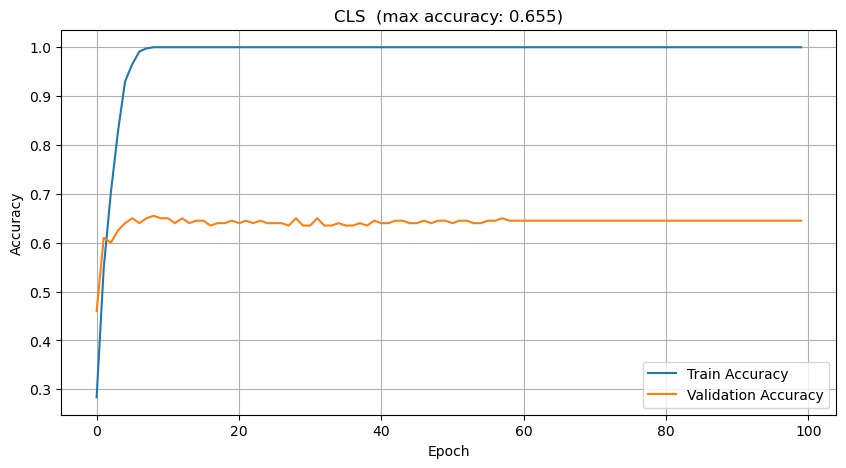

In [49]:
X, y = prepare_data(embeddings_data, labels, tokens= ['class_tokens'])
train_loader, test_loader, num_classes = create_dataloaders(X, y)
input_size = X.shape[1]

train_accuracy, test_accuracy = train_model(train_loader, test_loader, input_size, num_epochs=100)
plot_accuracy(train_accuracy, test_accuracy, 'CLS ')


100%|██████████| 100/100 [00:03<00:00, 32.89it/s]


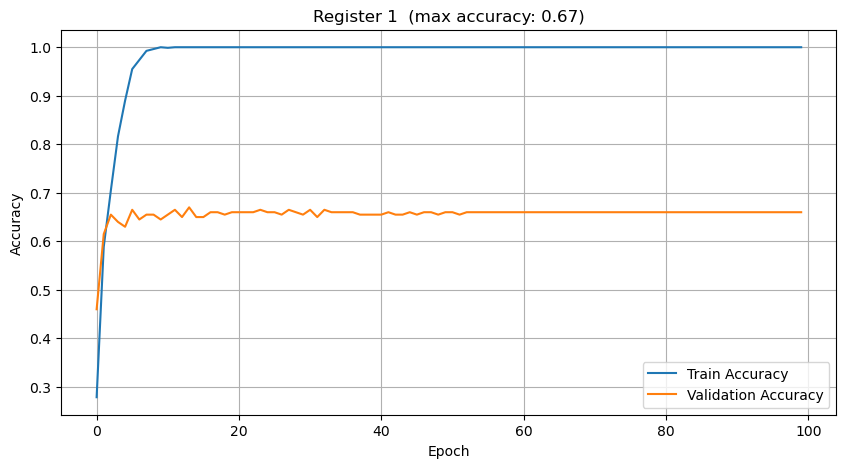

In [48]:
X, y = prepare_data(embeddings_data, labels, tokens= ['register_tokens'])
train_loader, test_loader, num_classes = create_dataloaders(X, y)
input_size = X.shape[1]

train_accuracy, test_accuracy = train_model(train_loader, test_loader, input_size, num_epochs=100)
plot_accuracy(train_accuracy, test_accuracy, 'Register 1 ')


100%|██████████| 100/100 [00:04<00:00, 24.39it/s]


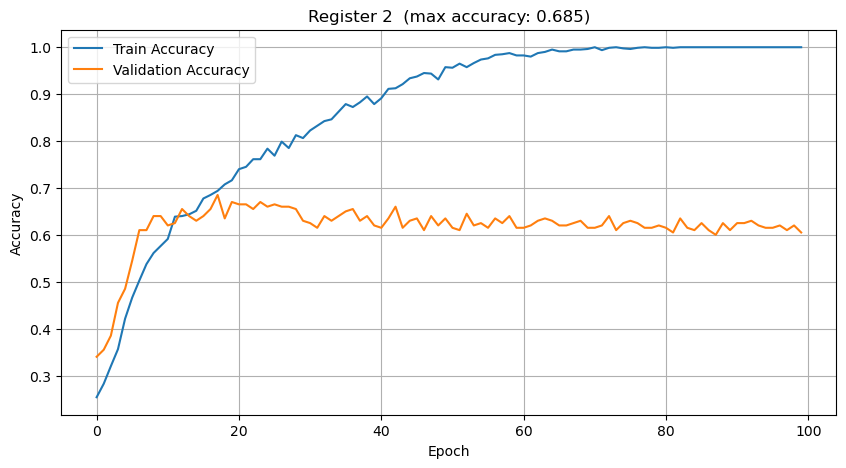

In [47]:
X, y = prepare_data(embeddings_data, labels, tokens= ['register_tokens'], reg=1)
train_loader, test_loader, num_classes = create_dataloaders(X, y)
input_size = X.shape[1]

train_accuracy, test_accuracy = train_model(train_loader, test_loader, input_size, num_epochs=100)
plot_accuracy(train_accuracy, test_accuracy, 'Register 2 ')


100%|██████████| 100/100 [00:03<00:00, 32.94it/s]


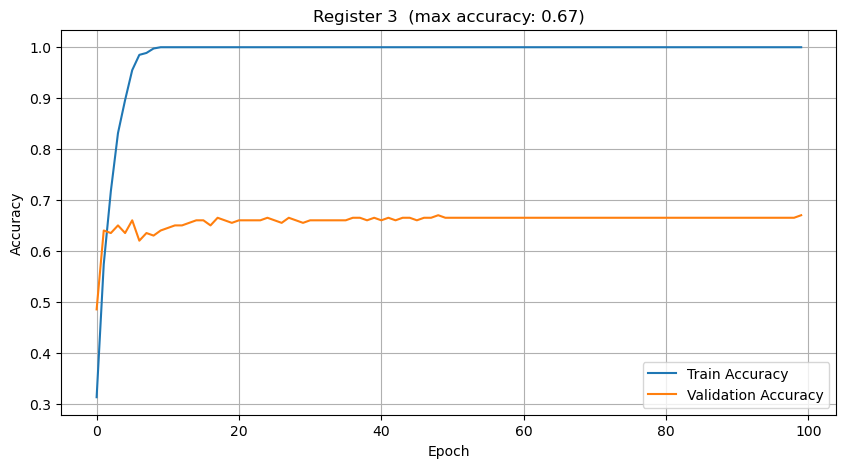

In [50]:
X, y = prepare_data(embeddings_data, labels, tokens= ['register_tokens'], reg=2)
train_loader, test_loader, num_classes = create_dataloaders(X, y)
input_size = X.shape[1]

train_accuracy, test_accuracy = train_model(train_loader, test_loader, input_size, num_epochs=100)
plot_accuracy(train_accuracy, test_accuracy, 'Register 3 ')

100%|██████████| 100/100 [00:03<00:00, 31.87it/s]


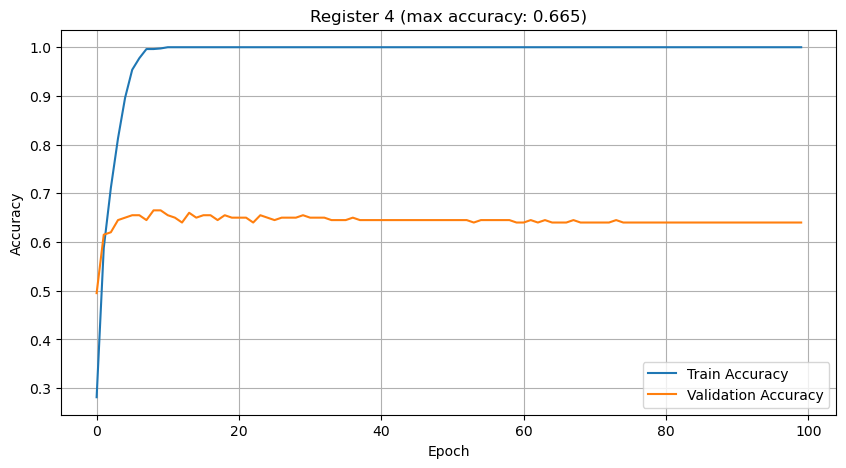

In [51]:
X, y = prepare_data(embeddings_data, labels, tokens= ['register_tokens'], reg=3)
train_loader, test_loader, num_classes = create_dataloaders(X, y)
input_size = X.shape[1]

train_accuracy, test_accuracy = train_model(train_loader, test_loader, input_size, num_epochs=100)
plot_accuracy(train_accuracy, test_accuracy, 'Register 4')

100%|██████████| 100/100 [00:07<00:00, 13.72it/s]


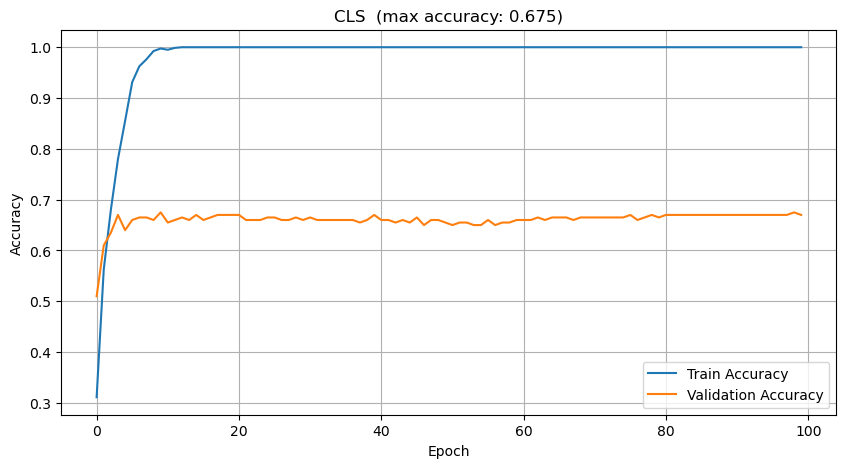

In [52]:
X, y = prepare_data(embeddings_data, labels, tokens= ['class_tokens', 'register_tokens'])
train_loader, test_loader, num_classes = create_dataloaders(X, y)
input_size = X.shape[1]

train_accuracy, test_accuracy = train_model(train_loader, test_loader, input_size, num_epochs=100)
plot_accuracy(train_accuracy, test_accuracy, 'CLS ')

Surprisingly the results here show that the register tokens actually outperform the CLS token with Register 2 performing the best out of them all. As expected, the combination of CLS and Register 2 improved the performance of the model. This result leads us to believe that there is not only crucial information being stored in the Register Tokens (Specifically register 2) but that this information may not be saved anywhere else as it is not stored in the CLS token.